# Brute force: one vehicle, one route

This notebook solves toy problem 1 by checking every possible tour and keeping the shortest. It is the exact classical baseline: it always finds the best answer, so every other solution can be checked against it.

The depot (point 0) is fixed as the start and the end. A tour is then an order of the other n − 1 locations, so there are (n − 1)! tours to check.

Distances follow the repository `README.md`: one distance per pair of locations, taken from the upper half of the matrix. The real one-way road distances are solved as well, for comparison.

In [1]:
import itertools
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

N_LOCATIONS = 10   # the depot plus 9 stops: every point in the data set

DATA_FILE = next(path for path in (Path("tallinn_osrm_matrix.json"), Path("../tallinn_osrm_matrix.json")) if path.exists())
data = json.loads(DATA_FILE.read_text(encoding="utf-8"))
ROAD_KM = np.array(data["distances"], dtype=float) / 1000
NAMES = [point["name"] for point in data["points"]]
LON_LAT = np.array([(point["lon"], point["lat"]) for point in data["points"]])


def distances(n, directed=False):
    """Distance matrix in km for the first n locations. Symmetric (upper half) unless `directed`."""
    road = ROAD_KM[:n, :n]
    if directed:
        return road.copy()
    upper = np.triu(road)
    return upper + upper.T


def brute_force(n, directed=False):
    """Shortest tour over the first n locations. Returns (km, tour, tours checked, seconds)."""
    start = time.perf_counter()
    d = distances(n, directed)
    tours = np.array(list(itertools.permutations(range(1, n))))
    km = d[0, tours[:, 0]] + d[tours[:, -1], 0]
    for step in range(n - 2):
        km = km + d[tours[:, step], tours[:, step + 1]]
    best = int(np.argmin(km))
    return float(km[best]), (0, *map(int, tours[best]), 0), len(tours), time.perf_counter() - start


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

# Every instance size

The instance with n locations uses the first n points of the matrix. With symmetric distances every loop appears twice, once per direction, so the table shows the direction that comes first in dictionary order.

In [2]:
rows = []
for n in range(5, N_LOCATIONS + 1):
    km, tour, checked, seconds = brute_force(n)
    road_km, road_tour, _, _ = brute_force(n, directed=True)
    rows.append([n, f"{checked:,}", f"{km:.3f}", " → ".join(map(str, tour)), f"{road_km:.3f}", " → ".join(map(str, road_tour)),
                 f"{seconds:.3f}"])
show_table(["Locations", "Tours checked", "Shortest, symmetric (km)", "Tour", "Shortest, one-way roads (km)", "Tour on one-way roads",
            "Seconds"], rows)

| Locations | Tours checked | Shortest, symmetric (km) | Tour | Shortest, one-way roads (km) | Tour on one-way roads | Seconds |
|---|---|---|---|---|---|---|
| 5 | 24 | 16.983 | 0 → 2 → 1 → 3 → 4 → 0 | 16.965 | 0 → 3 → 4 → 1 → 2 → 0 | 0.001 |
| 6 | 120 | 18.311 | 0 → 2 → 1 → 3 → 4 → 5 → 0 | 18.043 | 0 → 3 → 4 → 5 → 1 → 2 → 0 | 0.000 |
| 7 | 720 | 30.124 | 0 → 1 → 3 → 4 → 5 → 6 → 2 → 0 | 30.179 | 0 → 1 → 3 → 4 → 5 → 6 → 2 → 0 | 0.000 |
| 8 | 5,040 | 33.441 | 0 → 1 → 3 → 4 → 5 → 7 → 6 → 2 → 0 | 33.284 | 0 → 1 → 3 → 4 → 5 → 7 → 6 → 2 → 0 | 0.002 |
| 9 | 40,320 | 36.602 | 0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 2 → 0 | 36.692 | 0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 2 → 0 | 0.015 |
| 10 | 362,880 | 40.205 | 0 → 2 → 9 → 6 → 8 → 7 → 5 → 4 → 3 → 1 → 0 | 40.303 | 0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 9 → 2 → 0 | 0.190 |

# The route for all locations

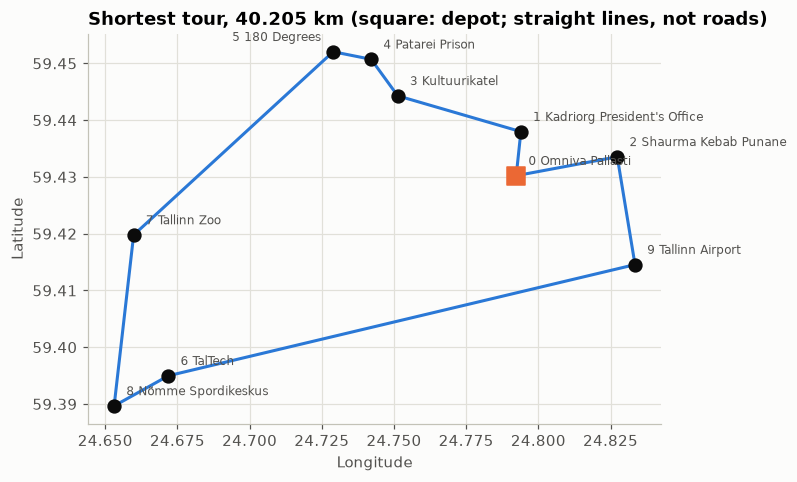

In [3]:
km, tour, checked, seconds = brute_force(N_LOCATIONS)
lon, lat = LON_LAT[:N_LOCATIONS, 0], LON_LAT[:N_LOCATIONS, 1]

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "figure.dpi": 110})
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(lon[list(tour)], lat[list(tour)], color="#2a78d6", linewidth=2, zorder=2)
ax.scatter(lon[1:], lat[1:], s=70, color="#0b0b0b", zorder=3)
ax.scatter(lon[:1], lat[:1], s=140, color="#eb6834", marker="s", zorder=3)
for i in range(N_LOCATIONS):
    # Point 5 sits just left of point 4, so its label goes on the other side.
    side = -1 if i == 5 else 1
    ax.annotate(f"{i} {NAMES[i].split(' (')[0]}", (lon[i], lat[i]), xytext=(8 * side, 7), textcoords="offset points",
                ha="right" if side < 0 else "left", fontsize=8, color="#52514e")
ax.set_aspect(1 / math.cos(math.radians(lat.mean())))
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title(f"Shortest tour, {km:.3f} km (square: depot; straight lines, not roads)")
plt.show()

# Measures for the leaderboard

Brute force is not a sampler, so the measures from `solutions/README.md` are simple. It checks every tour once and always returns a shortest one.

In [4]:
print(f"Locations:         {N_LOCATIONS}")
print(f"P(opt):            100 %")
print(f"P(valid):          100 %")
print(f"Mean gap:          0 %")
print(f"Cost evaluations:  {checked:,} (every tour once)")
print(f"Run time:          {seconds:.2f} s on this laptop")

Locations:         10
P(opt):            100 %
P(valid):          100 %
Mean gap:          0 %
Cost evaluations:  362,880 (every tour once)
Run time:          0.17 s on this laptop


# Why this does not scale

The number of tours is (n − 1)!. It grows faster than any power of n.

| Locations | Tours to check |
|---|---|
| 10 | 362,880 |
| 15 | about 8.7 × 10¹⁰ |
| 20 | about 1.2 × 10¹⁷ |
| 25 | about 6.2 × 10²³ |

At a million tours per second, 20 locations would take about 3,900 years. Exact classical methods such as dynamic programming or branch and cut do far better than brute force, and heuristics such as 2-opt handle thousands of locations. Brute force is here only as the ground truth for small instances.